<a href="https://colab.research.google.com/github/jungyouha/cds230/blob/main/lab7/pca_dry_bean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCA on the Dry Bean Dataset

**Dataset:** UCI Machine Learning Repository — *Dry Bean* (Koklu & Özkan, 2020).
A camera photographed 13,611 dry beans from 7 registered varieties
(Seker, Barbunya, Bombay, Cali, Dermason, Horoz, Sira). From each photo, 16 measurements were computed:
12 about size (area, perimeter, length, width, …) and 4 shape factors.

**Goal:** Compress the 16 measurements into a few principal components and see whether the
7 bean varieties separate — without telling PCA which bean is which.

**Before running:** download the zip from https://archive.ics.uci.edu/dataset/602/dry+bean ,
unzip it, and upload `Dry_Bean_Dataset.xlsx` with the 📁 folder icon on the left.
(If you skip the upload, the next cell downloads the data automatically with `ucimlrepo`.)

## Step 0 — Load the data

In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

if os.path.exists('Dry_Bean_Dataset.xlsx'):
    df = pd.read_excel('Dry_Bean_Dataset.xlsx')
else:
    # Fallback: download straight from UCI
    !pip install -q ucimlrepo
    from ucimlrepo import fetch_ucirepo
    bean = fetch_ucirepo(id=602)
    df = pd.concat([bean.data.features, bean.data.targets], axis=1)

print('Shape:', df.shape)   # expect (13611, 17)
print()
print(df['Class'].value_counts())
df.head()

Shape: (13611, 17)

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## Step 1 — Standardize (mean = 0, std = 1)
Area is measured in pixels (tens of thousands) while shape factors are tiny decimals (~0.001). Without scaling, Area and ConvexArea would dominate PCA.

In [12]:
feature_names = [c for c in df.columns if c != 'Class']   # all 16 measurements
x = df[feature_names].values
y = df['Class'].values          # kept aside — PCA never sees the variety labels

x = StandardScaler().fit_transform(x)

print('Features used:', len(feature_names))
print('Normalized data stats:')
print('  Mean : {:.6f}  (should be ~0)'.format(x.mean()))
print('  Std  : {:.6f}  (should be ~1)'.format(x.std()))
print('  Shape:', x.shape)

Features used: 16
Normalized data stats:
  Mean : 0.000000  (should be ~0)
  Std  : 1.000000  (should be ~1)
  Shape: (13611, 16)


## Why PCA should work well here — the features overlap a lot
Area, perimeter, length and diameter all describe 'how big is the bean', so they are highly correlated. PCA merges overlapping features like these into one component.

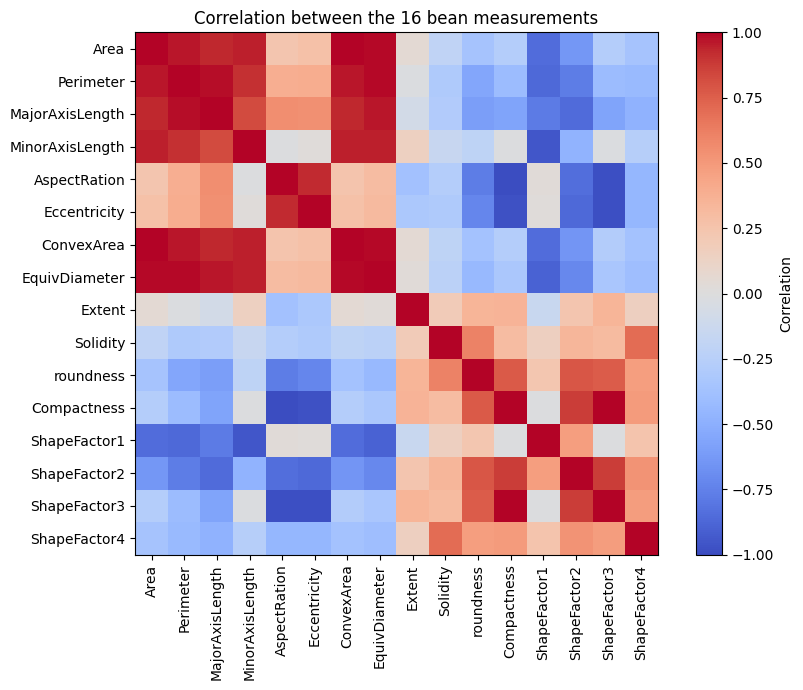

Most strongly related pairs:
Area          ConvexArea       1.000
Compactness   ShapeFactor3     0.999
Perimeter     EquivDiameter    0.991
AspectRation  Compactness      0.988
ConvexArea    EquivDiameter    0.985
Area          EquivDiameter    0.985


In [13]:
corr = pd.DataFrame(x, columns=feature_names).corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(feature_names)), feature_names, rotation=90)
plt.yticks(range(len(feature_names)), feature_names)
plt.title('Correlation between the 16 bean measurements')
plt.tight_layout()
plt.savefig('bean_correlation.png', dpi=150)
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().abs().sort_values(ascending=False))
print('Most strongly related pairs:')
print(pairs.head(6).round(3).to_string())

## Step 2 & 3 — PCA with 2 components

In [14]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(x)

pca_df = pd.DataFrame(pcs, columns=['PC1', 'PC2'])
pca_df['Class'] = y

print('PCA output shape:', pcs.shape)   # 13,611 beans x 2 components
print()
print(pca_df.head())

PCA output shape: (13611, 2)

        PC1       PC2  Class
0 -4.981561  1.824697  SEKER
1 -5.436792  2.932365  SEKER
2 -4.758088  1.826884  SEKER
3 -4.300541  2.003661  SEKER
4 -6.349340  4.088205  SEKER


## Explained variance

In [15]:
pc1_var, pc2_var = pca.explained_variance_ratio_

print('Explained variance per principal component:')
print('  PC1 : {:.1%}  - direction of greatest spread in the data'.format(pc1_var))
print('  PC2 : {:.1%}  - direction of second greatest spread'.format(pc2_var))
print('  ' + '-' * 45)
print('  Total: {:.1%}  of original information retained in 2D'.format(pc1_var + pc2_var))

Explained variance per principal component:
  PC1 : 55.5%  - direction of greatest spread in the data
  PC2 : 26.4%  - direction of second greatest spread
  ---------------------------------------------
  Total: 81.9%  of original information retained in 2D


## Visualize — 16 dimensions shown in 2

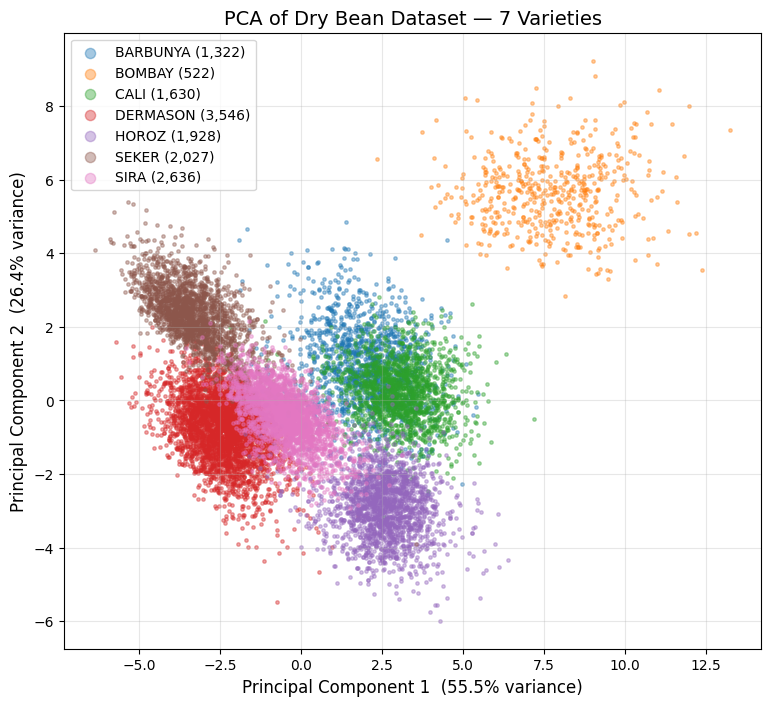

Plot saved as pca_dry_bean.png


In [16]:
classes = sorted(pca_df['Class'].unique())
colors = plt.cm.tab10(np.arange(len(classes)))

plt.figure(figsize=(9, 8))
for cls, color in zip(classes, colors):
    mask = pca_df['Class'] == cls
    plt.scatter(pca_df.loc[mask, 'PC1'], pca_df.loc[mask, 'PC2'],
                color=color, label=f'{cls} ({mask.sum():,})', alpha=0.4, s=6)

plt.xlabel('Principal Component 1  ({:.1%} variance)'.format(pc1_var), fontsize=12)
plt.ylabel('Principal Component 2  ({:.1%} variance)'.format(pc2_var), fontsize=12)
plt.title('PCA of Dry Bean Dataset — 7 Varieties', fontsize=14)
plt.legend(markerscale=3)
plt.grid(alpha=0.3)
plt.savefig('pca_dry_bean.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved as pca_dry_bean.png')

## How many components do we need?
PCA does not choose the number of components for us — we pick it based on a target such as 95%.

80% of variance needs  2 components (out of 16)
90% of variance needs  4 components (out of 16)
95% of variance needs  4 components (out of 16)
99% of variance needs  7 components (out of 16)


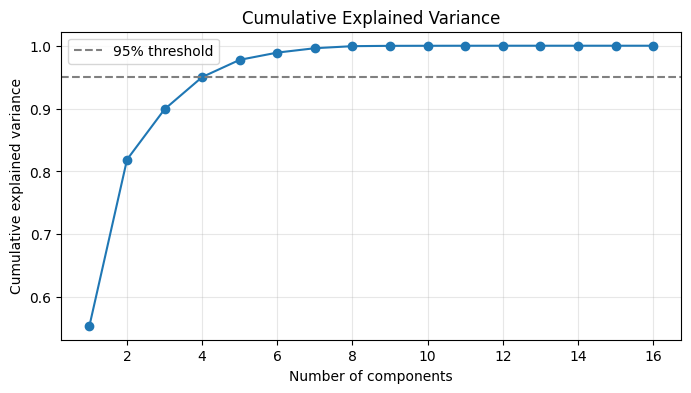

In [17]:
pca_full = PCA().fit(x)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_feat = len(feature_names)

for target in [0.80, 0.90, 0.95, 0.99]:
    k = np.argmax(cum >= target) + 1
    print(f'{target:.0%} of variance needs {k:2d} components (out of {n_feat})')

plt.figure(figsize=(8, 4))
plt.plot(range(1, n_feat + 1), cum, marker='o')
plt.axhline(0.95, color='gray', linestyle='--', label='95% threshold')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('pca_dry_bean_cumulative.png', dpi=150, bbox_inches='tight')
plt.show()

## What do PC1 and PC2 mean? (Loadings)
Use the top features to give each component a human-readable label.

In [18]:
loadings = pd.DataFrame(pca.components_.T, index=feature_names, columns=['PC1', 'PC2'])

for pc in ['PC1', 'PC2']:
    top = loadings[pc].abs().sort_values(ascending=False).head(6).index
    print(f'Top features for {pc}:')
    print(loadings.loc[top, pc].round(3).to_string())
    print()

Top features for PC1:
MajorAxisLength    0.326
ShapeFactor2      -0.315
Perimeter          0.311
EquivDiameter      0.297
ConvexArea         0.283
Area               0.282

Top features for PC2:
MinorAxisLength    0.343
ShapeFactor1      -0.333
AspectRation      -0.331
Compactness        0.329
ShapeFactor3       0.328
Eccentricity      -0.319



## Where does each variety sit? (average scores)

In [19]:
summary = pca_df.groupby('Class')[['PC1', 'PC2']].mean().round(2)
summary['Avg Area (pixels)'] = df.groupby('Class')['Area'].mean().round(0)
print(summary.sort_values('PC1'))

           PC1   PC2  Avg Area (pixels)
Class                                  
SEKER    -3.31  2.31            39881.0
DERMASON -2.41 -0.75            32119.0
SIRA     -0.50 -0.42            44729.0
BARBUNYA  1.97  0.98            69804.0
HOROZ     2.54 -2.88            53649.0
CALI      3.08  0.22            75538.0
BOMBAY    7.75  5.65           173485.0


## Automatic plain-language summary (uses your actual numbers)

In [20]:
k95 = np.argmax(cum >= 0.95) + 1
order = summary.sort_values('PC1').index.tolist()
print(f'''
- We looked at {len(df):,} beans from {len(classes)} varieties, each described by {n_feat} measurements.
- Squeezing the {n_feat} measurements into 2 summary scores keeps {pc1_var + pc2_var:.1%} of the information
  (PC1 {pc1_var:.1%} + PC2 {pc2_var:.1%}). Keeping 95% needs only {k95} of {n_feat} scores.
- Ordered from lowest to highest PC1 score: {", ".join(order)}.
- Biggest beans on average: {summary["Avg Area (pixels)"].idxmax()}; smallest: {summary["Avg Area (pixels)"].idxmin()}.
''')


- We looked at 13,611 beans from 7 varieties, each described by 16 measurements.
- Squeezing the 16 measurements into 2 summary scores keeps 81.9% of the information
  (PC1 55.5% + PC2 26.4%). Keeping 95% needs only 4 of 16 scores.
- Ordered from lowest to highest PC1 score: SEKER, DERMASON, SIRA, BARBUNYA, HOROZ, CALI, BOMBAY.
- Biggest beans on average: BOMBAY; smallest: DERMASON.




I used the Dry Bean dataset, which contains 13,611 beans from seven different varieties with 16 features. I applied PCA to reduce the 16 features to two principal components. The two components explained 81.9% of the total variance. The graph shows that some bean varieties are clearly separated, while others overlap. I also found that four components are enough to explain 95% of the variance. This shows that PCA can reduce the number of features while keeping most of the important patterns in the data.